#**스마트폰 센서 데이터 기반 모션 분류**
# 단계2 : 기본 모델링


## 0.미션

* 데이터 전처리
    * 가변수화, 데이터 분할, NaN 확인 및 조치, 스케일링 등 필요한 전처리 수행
* 다양한 알고리즘으로 분류 모델 생성
    * 최소 4개 이상의 알고리즘을 적용하여 모델링 수행
    * 성능 비교
    * 각 모델의 성능을 저장하는 별도 데이터 프레임을 만들고 비교
* 옵션 : 다음 사항은 선택사항입니다. 시간이 허용하는 범위 내에서 수행하세요.
    * 상위 N개 변수를 선정하여 모델링 및 성능 비교
        * 모델링에 항상 모든 변수가 필요한 것은 아닙니다.
        * 변수 중요도 상위 N개를 선정하여 모델링하고 타 모델과 성능을 비교하세요.
        * 상위 N개를 선택하는 방법은, 변수를 하나씩 늘려가며 모델링 및 성능 검증을 수행하여 적절한 지점을 찾는 것입니다.

## 1.환경설정

In [ ]:
import random
import numpy as np
import os

# 1. 파이썬 자체 난수 고정
random.seed(42)

# 2. 넘파이 난수 고정
np.random.seed(42)

# 3. 텐서플로우 사용하는 경우 (딥러닝)
import tensorflow as tf
tf.random.set_seed(42)

# 4. (선택) 실행 환경 내에서 다른 난수도 통제하고 싶을 때
os.environ['PYTHONHASHSEED'] = '42'

### (1) 라이브러리 불러오기

* 세부 요구사항
    - 기본적으로 필요한 라이브러리를 import 하도록 코드가 작성되어 있습니다.
    - 필요하다고 판단되는 라이브러리를 추가하세요.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 필요하다고 판단되는 라이브러리를 추가하세요.
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
# from xgboost import XGBClassifier
# import lightgbm as lgb
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.metrics import *
import joblib

* 함수 생성

In [ ]:
# 변수의 특성 중요도 계산하기
def plot_feature_importance(importance, names, result_only = False, topn = 'all'):
    feature_importance = np.array(importance)
    feature_name = np.array(names)

    data={'feature_name':feature_name,'feature_importance':feature_importance}
    fi_temp = pd.DataFrame(data)

    #변수의 특성 중요도 순으로 정렬하기
    fi_temp.sort_values(by=['feature_importance'], ascending=False,inplace=True)
    fi_temp.reset_index(drop=True, inplace = True)

    if topn == 'all' :
        fi_df = fi_temp.copy()
    else :
        fi_df = fi_temp.iloc[:topn]

    #변수의 특성 중요도 그래프로 그리기
    if result_only == False :
        plt.figure(figsize=(10,20))
        sns.barplot(x='feature_importance', y='feature_name', data = fi_df)

        plt.xlabel('importance')
        plt.ylabel('feature name')
        plt.grid()

    return fi_df

### (2) 데이터 불러오기

* 주어진 데이터셋
    * data01_train.csv : 학습 및 검증용
* 세부 요구사항
    - 전체 데이터 'data01_train.csv' 를 불러와 'data' 이름으로 저장합니다.
        - data에서 변수 subject는 삭제합니다.
    - 데이터프레임에 대한 기본 정보를 확인합니다.( .head(), .shape 등)

#### 1) 데이터 로딩

In [ ]:
train_data = pd.read_csv('data01_train.csv')

In [ ]:
test_data = pd.read_csv('data01_test.csv')

#### 2) 기본 정보 조회

In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1438 entries, 0 to 1437
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(562), object(1)
memory usage: 6.2+ MB


In [ ]:
train_data.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.816696,-0.042494,-0.044218,0.307873,0.072790,-0.601120,0.331298,0.165163,21.0,STANDING
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.693515,-0.062899,0.388459,-0.765014,0.771524,0.345205,-0.769186,-0.147944,15.0,LAYING
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.829311,0.000265,-0.525022,-0.891875,0.021528,-0.833564,0.202434,-0.032755,11.0,STANDING
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,-0.408956,-0.255125,0.612804,0.747381,-0.072944,-0.695819,0.287154,0.111388,17.0,WALKING
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.563437,-0.044344,-0.845268,-0.974650,-0.887846,-0.705029,0.264952,0.137758,17.0,WALKING_DOWNSTAIRS


In [ ]:
train_data.describe()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject
count,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,...,1437.000000,1437.000000,1437.000000,1437.000000,1437.000000,1437.000000,1437.000000,1437.000000,1437.000000,1437.000000
mean,0.274818,-0.017595,-0.111058,-0.571672,-0.469902,-0.569280,-0.598891,-0.486825,-0.571089,-0.427658,...,-0.311666,-0.632611,0.008662,-0.004053,-0.007767,-0.006822,-0.517924,0.080668,-0.038625,17.293667
std,0.067062,0.044937,0.064324,0.451475,0.509682,0.427805,0.426416,0.492587,0.422920,0.547601,...,0.312289,0.299495,0.354695,0.454990,0.614533,0.482534,0.488347,0.280119,0.271802,8.970009
min,-0.503823,-0.684893,-1.000000,-0.999533,-0.998483,-0.999454,-0.999243,-0.998660,-0.999755,-0.948813,...,-0.912384,-0.998619,-0.976580,-1.000000,-0.999218,-0.995100,-0.992164,-1.000000,-0.965728,1.000000
25%,0.260674,-0.025728,-0.123116,-0.991887,-0.974043,-0.978406,-0.992943,-0.974194,-0.978380,-0.935211,...,-0.538521,-0.845203,-0.137197,-0.302336,-0.531266,-0.383470,-0.810045,0.023863,-0.117278,8.000000
50%,0.277197,-0.017169,-0.108942,-0.826728,-0.604750,-0.617871,-0.840325,-0.610840,-0.603624,-0.720473,...,-0.350368,-0.716803,0.007628,0.003327,-0.001556,0.008693,-0.714009,0.192331,0.013870,19.000000
75%,0.290928,-0.010040,-0.097538,-0.221807,-0.010401,-0.235017,-0.269531,-0.042635,-0.238975,0.021014,...,-0.135859,-0.513507,0.165952,0.283408,0.496655,0.369611,-0.547626,0.252754,0.127597,25.000000
max,0.632627,1.000000,0.719094,0.876942,0.916238,1.000000,0.852822,0.967664,1.000000,0.907994,...,0.989538,0.956845,0.946651,1.000000,0.998702,0.996078,0.977344,0.478157,0.999014,30.000000


## **2. 데이터 전처리**

* 가변수화, 데이터 분할, NaN 확인 및 조치, 스케일링 등 필요한 전처리를 수행한다.


In [ ]:
train_data.drop('subject', axis=1, inplace=True)

In [ ]:
train_data.head(3)

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.487737,-0.816696,-0.042494,-0.044218,0.307873,0.072790,-0.601120,0.331298,0.165163,STANDING
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.237820,-0.693515,-0.062899,0.388459,-0.765014,0.771524,0.345205,-0.769186,-0.147944,LAYING
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.535287,-0.829311,0.000265,-0.525022,-0.891875,0.021528,-0.833564,0.202434,-0.032755,STANDING


In [ ]:
sum(train_data.isna().sum())

477

### (1) 데이터 분할1 : x, y

* 세부 요구사항
    - x, y로 분할합니다.

In [ ]:
X_train = train_data.drop('Activity', axis=1)
y_train = train_data.loc[:, 'Activity']

In [ ]:
X_test = test_data.drop(['subject', 'Activity'], axis=1)
y_test = test_data.loc[:, 'Activity']

In [ ]:
y_train.unique()

array(['STANDING', 'LAYING', 'WALKING', 'WALKING_DOWNSTAIRS',
       'WALKING_UPSTAIRS', 'SITTING', nan], dtype=object)

In [ ]:
y_test.unique()

array(['SITTING', 'STANDING', 'WALKING', 'WALKING_UPSTAIRS', 'LAYING',
       'WALKING_DOWNSTAIRS'], dtype=object)

### (2) 스케일링(필요시)


* 세부 요구사항
    - 스케일링을 필요로 하는 알고리즘 사용을 위해서 코드 수행
    - min-max 방식 혹은 standard 방식 중 한가지 사용.

In [ ]:
# 스케일링 필요 없다고 판단

### (3) 데이터분할2 : train, validation

* 세부 요구사항
    - train : val = 8 : 2 혹은 7 : 3
    - random_state 옵션을 사용하여 다른 모델과 비교를 위해 성능이 재현되도록 합니다.

In [ ]:
# X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## **3. 기본 모델링**



* 세부 요구사항
    - 최소 4개 이상의 알고리즘을 적용하여 모델링을 수행한다.
    - 각 알고리즘별로 전체 변수로 모델링, 상위 N개 변수를 선택하여 모델링을 수행하고 성능 비교를 한다.
    - (옵션) 알고리즘 중 1~2개에 대해서, 변수 중요도 상위 N개를 선정하여 모델링하고 타 모델과 성능을 비교.
        * 상위 N개를 선택하는 방법은, 변수를 하나씩 늘려가며 모델링 및 성능 검증을 수행하여 적절한 지점을 찾는 것이다.

In [ ]:
acc_df = pd.DataFrame({'모델': [],
                       'default_정확도(교차검증)': [],
                       'default_정확도(테스트)': [],
                       'default_정확도(fi_교차검증)': [],
                       'default_정확도(fi_테스트)': []
                      })
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)


In [ ]:
kappa_df = pd.DataFrame({'모델': [],
                       'default_kappa(교차검증)': [],
                       'default_kappa(테스트)': [],
                      })
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트)


In [ ]:
kappa_scorer = make_scorer(cohen_kappa_score)

### (1) 알고리즘1 : RandomForest

In [ ]:
rf_model = RandomForestClassifier(random_state=42)
scores = cross_validate(rf_model, X_train, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9772146411665771
평균 카파  : 0.9725802672246608


In [ ]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9782460910944936
[[292   0   0   0   0   0]
 [  0 242  12   0   0   0]
 [  0  11 276   0   0   0]
 [  0   0   0 224   0   4]
 [  0   0   0   1 192   2]
 [  0   0   0   1   1 213]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.96      0.95      0.95       254
          STANDING       0.96      0.96      0.96       287
           WALKING       0.99      0.98      0.99       228
WALKING_DOWNSTAIRS       0.99      0.98      0.99       195
  WALKING_UPSTAIRS       0.97      0.99      0.98       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9738


In [ ]:
joblib.dump(rf_model, 'rf_model_default.pkl')

['rf_model_default.pkl']

In [ ]:
new_row = pd.DataFrame([{'모델': 'RandomForest', 'default_정확도(교차검증)': np.mean(scores['test_accuracy']), 'default_정확도(테스트)': accuracy_score(y_test, y_pred)}])
acc_df = pd.concat([acc_df, new_row], ignore_index=True)

In [ ]:
new_row = pd.DataFrame([{'모델': 'RandomForest', 'default_kappa(교차검증)': np.mean(scores['test_kappa']), 'default_kappa(테스트)': cohen_kappa_score(y_test, y_pred)}])
kappa_df = pd.concat([kappa_df, new_row], ignore_index=True)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트)
0,RandomForest,0.97258,0.973782


### (2) 알고리즘2 : LogisticRegression

In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
scores = cross_validate(lr_model, X_train, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9833363676821621
평균 카파  : 0.9799456385574603


In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9809653297076818
[[290   0   0   0   2   0]
 [  0 242  12   0   0   0]
 [  0  12 274   0   0   1]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       292
           SITTING       0.95      0.95      0.95       254
          STANDING       0.96      0.95      0.96       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       0.99      1.00      0.99       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9771


In [ ]:
joblib.dump(lr_model, 'lr_model_default.pkl')

['lr_model_default.pkl']

In [ ]:
new_row = pd.DataFrame([{'모델': 'LogisticRegression', 'default_정확도(교차검증)': np.mean(scores['test_accuracy']), 'default_정확도(테스트)': accuracy_score(y_test, y_pred)}])
acc_df = pd.concat([acc_df, new_row], ignore_index=True)

In [ ]:
new_row = pd.DataFrame([{'모델': 'LogisticRegression', 'default_kappa(교차검증)': np.mean(scores['test_kappa']), 'default_kappa(테스트)': cohen_kappa_score(y_test, y_pred)}])
kappa_df = pd.concat([kappa_df, new_row], ignore_index=True)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,NaN,NaN
1,LogisticRegression,0.983336,0.980965,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트)
0,RandomForest,0.972580,0.973782
1,LogisticRegression,0.979946,0.977063


### (3) 알고리즘3 : SVM

In [ ]:
svm_model = SVC(random_state=42)
scores = cross_validate(svm_model, X_train, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9682027696380168
평균 카파  : 0.9617309883837846


In [ ]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.973487423521414
[[292   0   0   0   0   0]
 [  0 231  23   0   0   0]
 [  0  15 272   0   0   0]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.94      0.91      0.92       254
          STANDING       0.92      0.95      0.93       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       1.00      1.00      1.00       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.97      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.97      0.97      0.97      1471

Cohen's Kappa Score: 0.9680


In [ ]:
joblib.dump(svm_model, 'svm_model_default.pkl')

['svm_model_default.pkl']

In [ ]:
new_row = pd.DataFrame([{'모델': 'SVM', 'default_정확도(교차검증)': np.mean(scores['test_accuracy']), 'default_정확도(테스트)': accuracy_score(y_test, y_pred)}])
acc_df = pd.concat([acc_df, new_row], ignore_index=True)

In [ ]:
new_row = pd.DataFrame([{'모델': 'SVM', 'default_kappa(교차검증)': np.mean(scores['test_kappa']), 'default_kappa(테스트)': cohen_kappa_score(y_test, y_pred)}])
kappa_df = pd.concat([kappa_df, new_row], ignore_index=True)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,NaN,NaN
1,LogisticRegression,0.983336,0.980965,NaN,NaN
2,SVM,0.968203,0.973487,NaN,NaN


### (4) 알고리즘4 : DecisionTreeClassifier

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
scores = cross_validate(dt_model, X_train, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9348765164519504
평균 카파  : 0.9216217422297339


In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9401767505098573
[[290   2   0   0   0   0]
 [  0 232  22   0   0   0]
 [  0  25 262   0   0   0]
 [  0   0   0 214   1  13]
 [  0   0   0   1 186   8]
 [  0   0   0   7   9 199]]
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       292
           SITTING       0.90      0.91      0.90       254
          STANDING       0.92      0.91      0.92       287
           WALKING       0.96      0.94      0.95       228
WALKING_DOWNSTAIRS       0.95      0.95      0.95       195
  WALKING_UPSTAIRS       0.90      0.93      0.91       215

          accuracy                           0.94      1471
         macro avg       0.94      0.94      0.94      1471
      weighted avg       0.94      0.94      0.94      1471

Cohen's Kappa Score: 0.9279


In [ ]:
joblib.dump(dt_model, 'dt_model_default.pkl')

['dt_model_default.pkl']

In [ ]:
new_row = pd.DataFrame([{'모델': 'DecisionTreeClassifier', 'default_정확도(교차검증)': np.mean(scores['test_accuracy']), 'default_정확도(테스트)': accuracy_score(y_test, y_pred)}])
acc_df = pd.concat([acc_df, new_row], ignore_index=True)

In [ ]:
new_row = pd.DataFrame([{'모델': 'DecisionTreeClassifier', 'default_kappa(교차검증)': np.mean(scores['test_kappa']), 'default_kappa(테스트)': cohen_kappa_score(y_test, y_pred)}])
kappa_df = pd.concat([kappa_df, new_row], ignore_index=True)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,NaN,NaN
1,LogisticRegression,0.983336,0.980965,NaN,NaN
2,SVM,0.968203,0.973487,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트)
0,RandomForest,0.972580,0.973782
1,LogisticRegression,0.979946,0.977063
2,SVM,0.961731,0.968043
3,RandomForest,0.921622,0.927913


In [ ]:
acc_df.to_csv('모델 정확도(디폴트).csv', index=False, encoding='utf-8-sig')

## ================일단 여기까지=====================

### (5) 알고리즘5 : XGBoost

In [ ]:
# le = LabelEncoder()
# y_xgb = le.fit_transform(y)

In [ ]:
# X_train_xgb, X_val_xgb, y_train_xgb, y_val_xgb = train_test_split(X, y_xgb, test_size=0.2, random_state=42)

In [ ]:
# XGB_model = XGBClassifier(random_state=42)
# XGB_model.fit(X_train_xgb, y_train_xgb)

# y_pred = XGB_model.predict(X_val_xgb)
# y_pred = le.inverse_transform(y_pred)

# y_val = le.inverse_transform(y_val_xgb)

# print('accuracy :',accuracy_score(y_val, y_pred))
# print('='*60)
# print(confusion_matrix(y_val, y_pred))
# print('='*60)
# print(classification_report(y_val, y_pred))

In [ ]:
# new_row = pd.DataFrame([{'model': 'XGBoost', 'accuracy': accuracy_score(y_val, y_pred)}])
# acc_df = pd.concat([acc_df, new_row], ignore_index=True)

In [ ]:
# acc_df

### (6) 알고리즘6 : LightGBM

In [ ]:
# X_lgb = X.copy()
# X_lgb.columns = [f'feature_{i}' for i in range(X.shape[1])]

In [ ]:
# le = LabelEncoder()
# y_lgb = le.fit_transform(y)

In [ ]:
# X_train_lgb, X_val_lgb, y_train_lgb, y_val_lgb = train_test_split(X_lgb, y_lgb, test_size=0.2, random_state=42)

In [ ]:
# LGB_model = lgb.LGBMClassifier(random_state=42)
# LGB_model.fit(X_train_lgb, y_train_lgb)  # 경고문이 나옴. 너무 많은 특성 중 쓸모 없는 게 많을 때 이런 경고가 뜰 수 있음. 특성 중요도로 피처 수를 조절할 필요가 있음.

# y_pred = LGB_model.predict(X_val_lgb)
# y_pred = le.inverse_transform(y_pred)

# y_val= le.inverse_transform(y_val_lgb)

# print('accuracy :',accuracy_score(y_val, y_pred))
# print('='*60)
# print(confusion_matrix(y_val, y_pred))
# print('='*60)
# print(classification_report(y_val, y_pred))

### (7) 알고리즘7 : ANN

In [ ]:
# X = data.drop('Activity', axis=1)
# y = data.loc[:, 'Activity'].values

In [ ]:
# from sklearn.preprocessing import LabelEncoder
# le = LabelEncoder()
# y_encoded = le.fit_transform(y)

In [ ]:
# x_train, x_val, y_train, y_val = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

In [ ]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Input, Dense, Dropout
# model = Sequential()

In [ ]:
# model.add(Input(shape=(561,)))
# model.add(Dense(283, activation='relu'))
# model.add(Dropout(0.3))
# model.add(Dense(units=283, activation='relu'))
# model.add(Dropout(0.3))
# model.add(Dense(units=283, activation='relu'))
# model.add(Dropout(0.3))
# model.add(Dense(units=6, activation='softmax'))

In [ ]:
# model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# model.fit(x_train, y_train, batch_size = 32, epochs = 50)

In [ ]:
# y_pred = model.predict(x_val)
# y_pred = np.argmax(y_pred, axis=1)

In [ ]:
# y_val = le.inverse_transform(y_val)
# y_pred = le.inverse_transform(y_pred)
# print('accuracy :',accuracy_score(y_val, y_pred))
# print('='*60)
# print(confusion_matrix(y_val, y_pred))
# print('='*60)
# print(classification_report(y_val, y_pred))

## 특성 중요도(랜덤 포레스트에서 추출)

In [ ]:
rf_model = joblib.load('rf_model_default.pkl')

In [ ]:
RFmodel_fi_df = plot_feature_importance(rf_model.feature_importances_, list(X_train), True)
RFmodel_fi_df

,feature_name,feature_importance
0,"angle(X,gravityMean)",0.036764
1,tGravityAcc-mean()-X,0.034548
2,tGravityAcc-max()-X,0.030082
3,tGravityAcc-mean()-Y,0.028826
4,tGravityAcc-energy()-X,0.023418
...,...,...
556,fBodyGyro-min()-X,0.000099
557,"fBodyAccJerk-bandsEnergy()-33,48.1",0.000089
558,fBodyAccJerk-entropy()-X,0.000084
559,tGravityAccMag-min(),0.000081


In [ ]:
data = pd.read_csv('data01_train.csv')
data.drop('subject', axis=1, inplace=True)
target = data.loc[:, 'Activity']

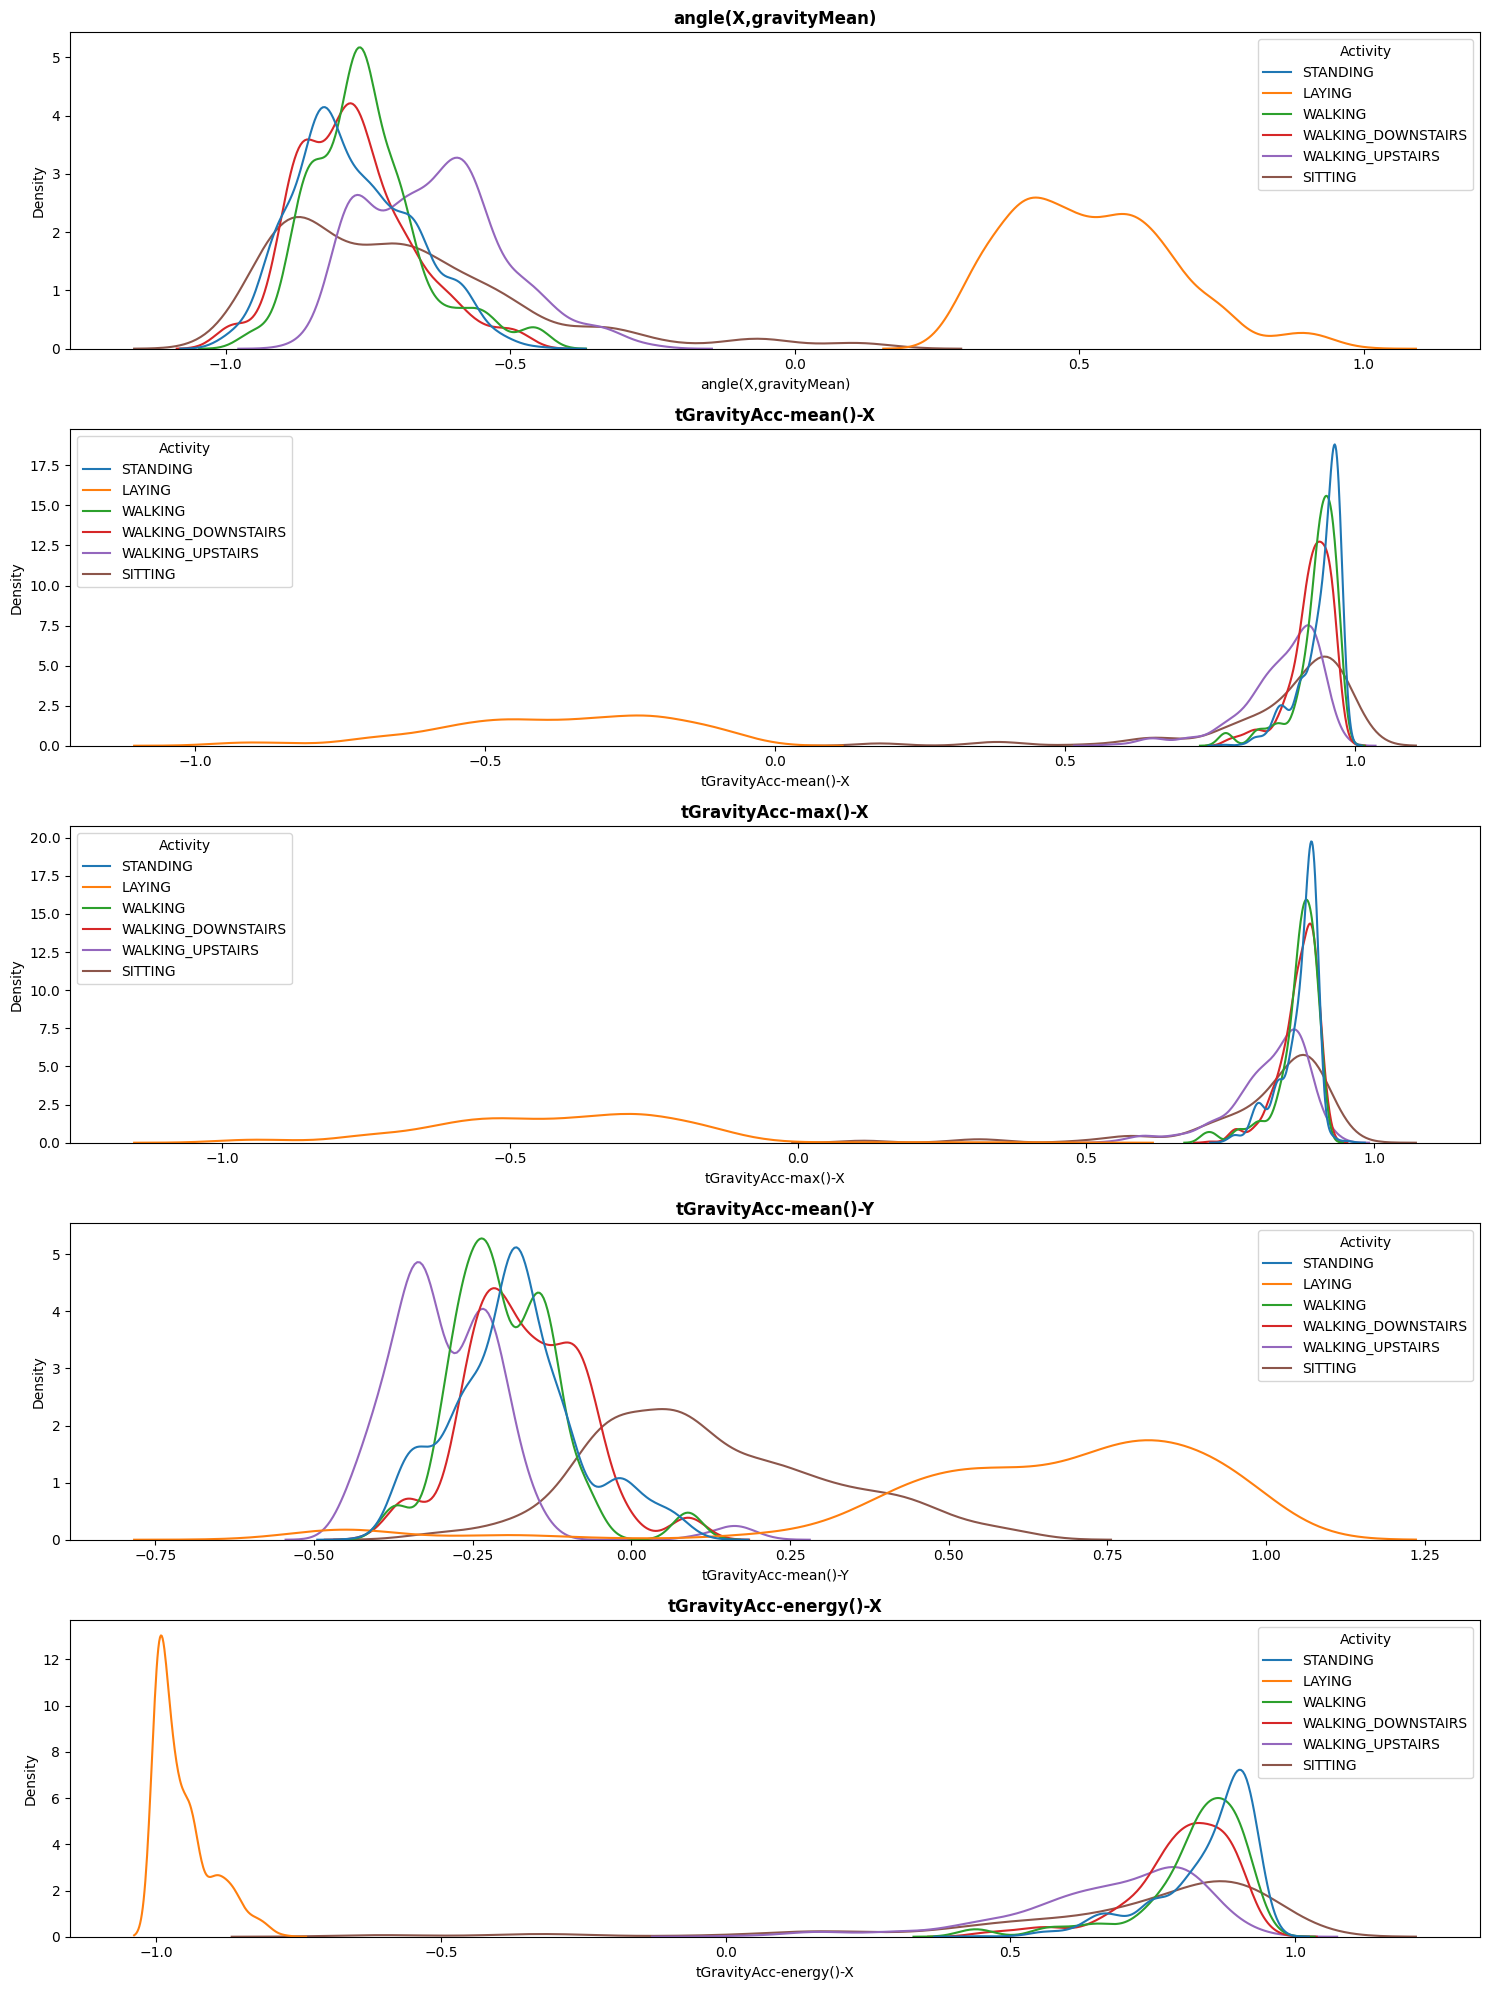

In [ ]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = RFmodel_fi_df.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

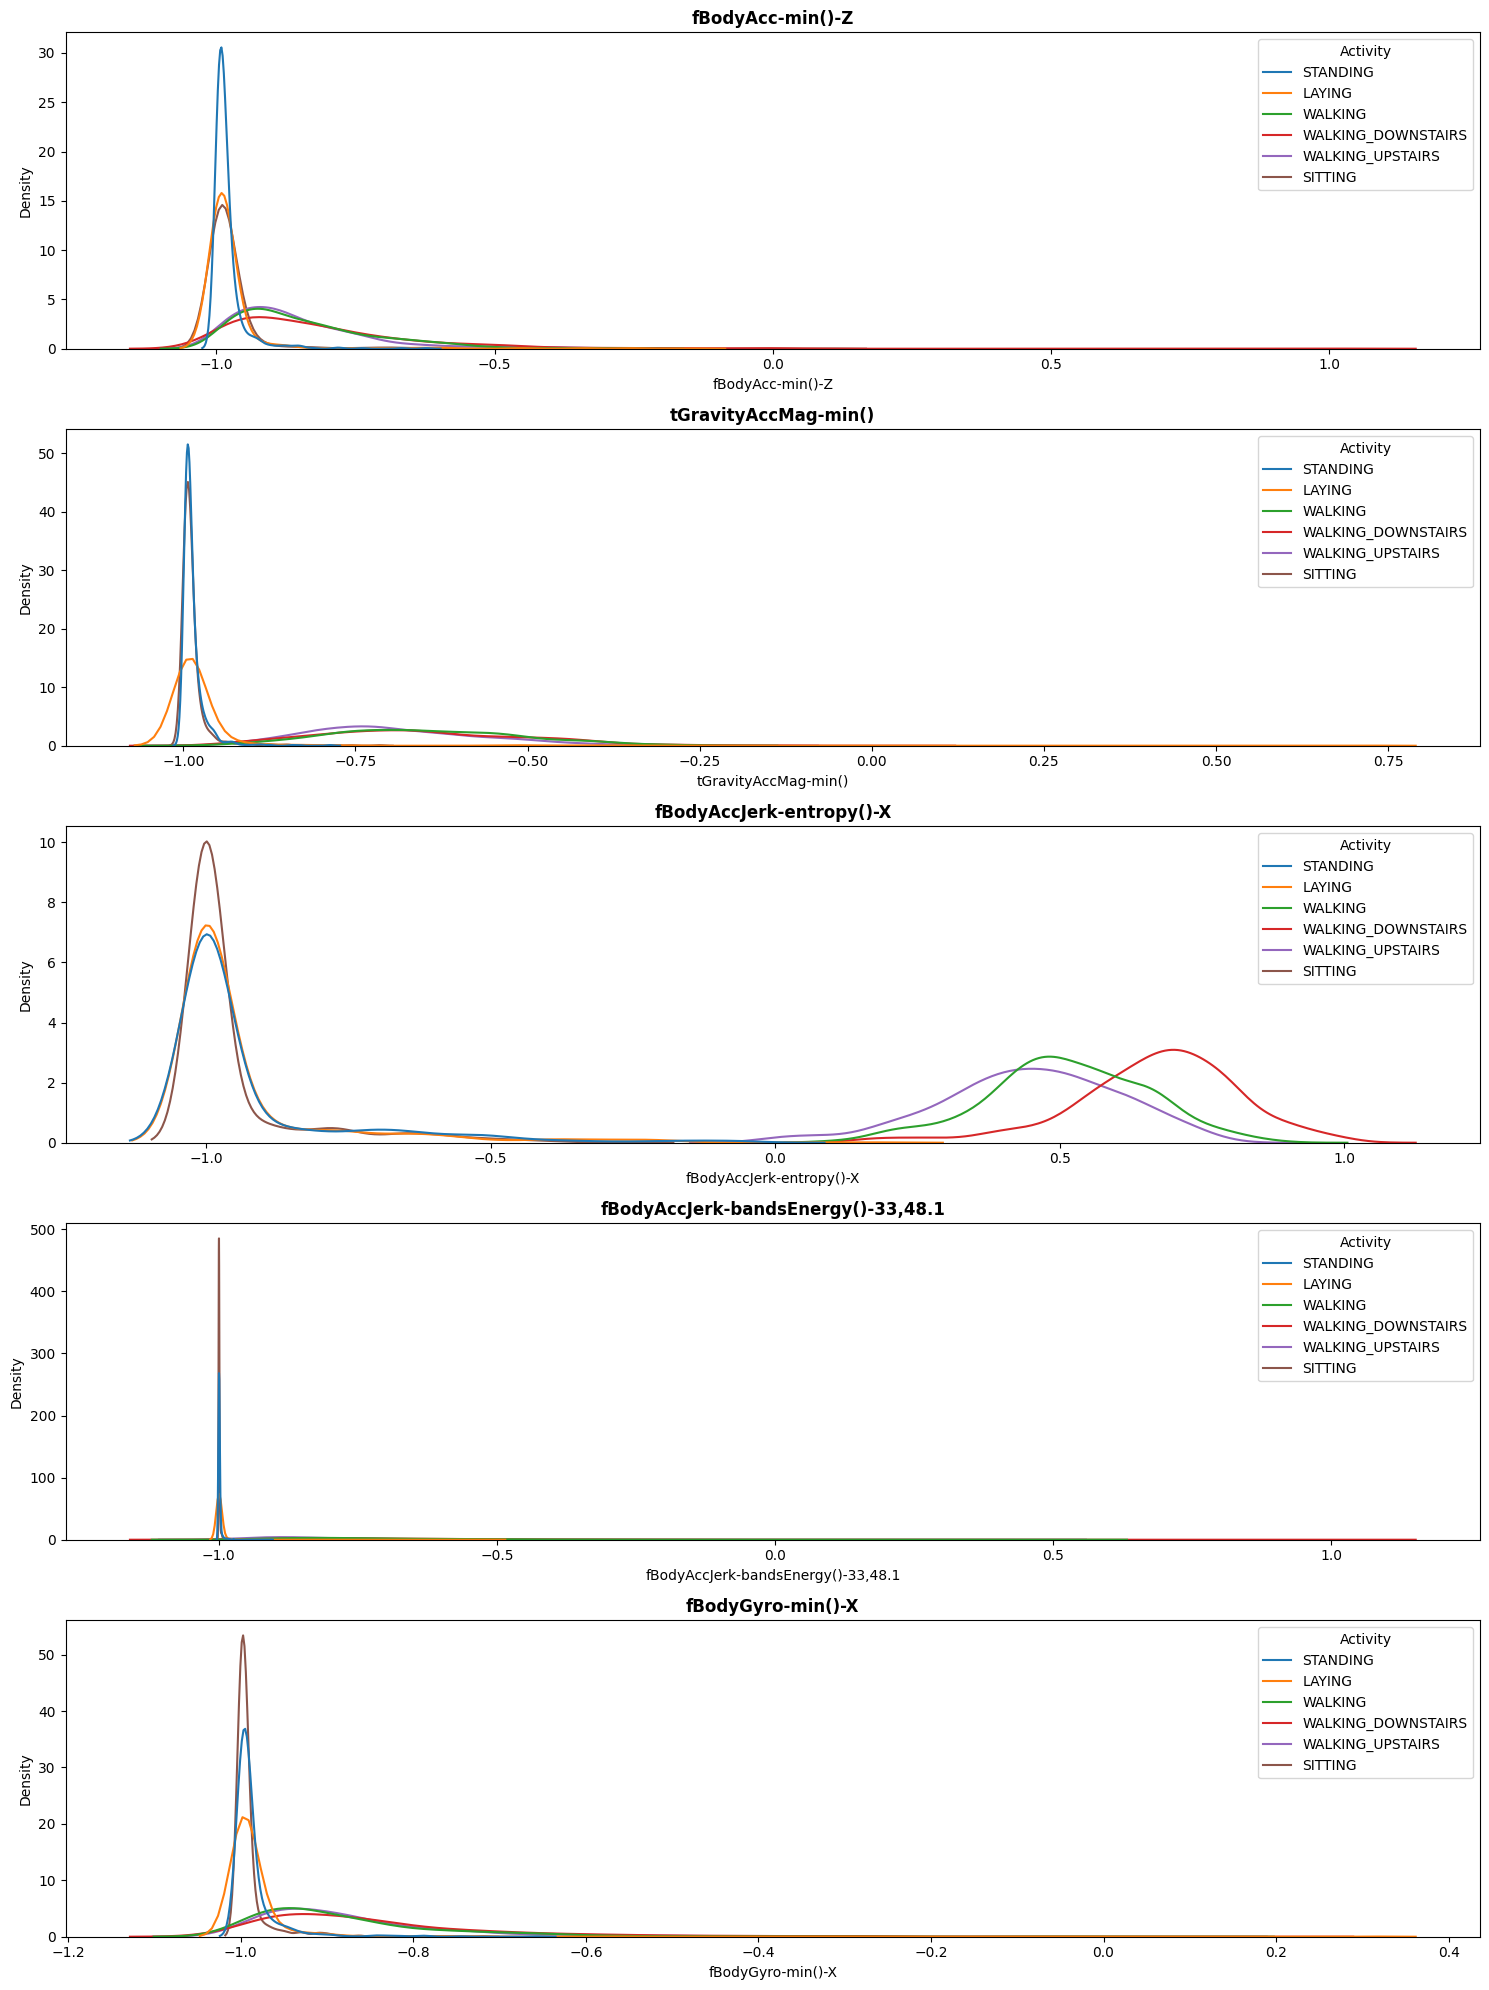

In [ ]:
# 중요도 하위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(1,6):
    var = RFmodel_fi_df.iloc[-i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i-1])
    ax[i-1].set_title(f'{var}', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# 기존 변수 개수
len(RFmodel_fi_df)

561

In [ ]:
RFmodel_fi_df['cum_importance'] = RFmodel_fi_df['feature_importance'].cumsum() / RFmodel_fi_df['feature_importance'].sum()

In [ ]:
# 누적 중요도 기준 95%까지 필요한 변수 개수
selected_features = RFmodel_fi_df[RFmodel_fi_df['cum_importance'] <= 0.95]['feature_importance']
print(f"누적 중요도 95%까지 선택된 변수 개수: {len(selected_features)}")

누적 중요도 95%까지 선택된 변수 개수: 319


In [ ]:
N = 319
selected_cum_importance = RFmodel_fi_df.loc[:N-1, 'feature_importance'].sum()
print(f"상위 {N}개 변수의 누적 중요도: {selected_cum_importance:.4f}")

상위 319개 변수의 누적 중요도: 0.9497


In [ ]:
X_train_fi = train_data[RFmodel_fi_df['feature_name'][:319]]
y_train_fi = train_data.loc[:, 'Activity']

In [ ]:
X_test_fi = test_data[RFmodel_fi_df['feature_name'][:319]]

### 랜덤 포레스트

In [ ]:
rf_model = RandomForestClassifier(random_state=42)
scores = cross_validate(rf_model, X_train_fi, y_train_fi, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9795961715187349
평균 카파  : 0.9754463298185649


In [ ]:
random_forest_model_fi = RandomForestClassifier(random_state=42)

random_forest_model_fi.fit(X_train_fi, y_train_fi)
y_pred = random_forest_model_fi.predict(X_test_fi)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9782460910944936
[[292   0   0   0   0   0]
 [  0 243  11   0   0   0]
 [  0  15 272   0   0   0]
 [  0   0   0 224   0   4]
 [  0   0   0   0 194   1]
 [  0   0   0   0   1 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.94      0.96      0.95       254
          STANDING       0.96      0.95      0.95       287
           WALKING       1.00      0.98      0.99       228
WALKING_DOWNSTAIRS       0.99      0.99      0.99       195
  WALKING_UPSTAIRS       0.98      1.00      0.99       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9738


In [ ]:
joblib.dump(rf_model, 'rf_model_default_fi.pkl')

['rf_model_default_fi.pkl']

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,NaN,NaN
1,LogisticRegression,0.983336,0.980965,NaN,NaN
2,SVM,0.968203,0.973487,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,NaN,NaN


In [ ]:
acc_df.loc[0, 'default_정확도(fi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[0, 'default_정확도(fi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[0, 'default_kappa(fi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[0, 'default_kappa(fi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246
1,LogisticRegression,0.983336,0.980965,NaN,NaN
2,SVM,0.968203,0.973487,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785
1,LogisticRegression,0.979946,0.977063,NaN,NaN
2,SVM,0.961731,0.968043,NaN,NaN
3,RandomForest,0.921622,0.927913,NaN,NaN


### LinearRegression

In [ ]:
# 랜덤 포레스트에서 추출한 중요도 상위 특성 활용
lr_model = LogisticRegression(max_iter=1000, random_state=42)
scores = cross_validate(lr_model, X_train_fi, y_train_fi, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9765349470289391
평균 카파  : 0.9717605043159245


In [ ]:
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_fi, y_train_fi)
y_pred = logistic_model.predict(X_test_fi)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9802855200543847
[[290   0   0   0   2   0]
 [  0 240  14   0   0   0]
 [  0  12 275   0   0   0]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       292
           SITTING       0.95      0.94      0.95       254
          STANDING       0.95      0.96      0.95       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       0.99      1.00      0.99       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9762


In [ ]:
joblib.dump(lr_model, 'lr_model_default_fi.pkl')

['lr_model_default_fi.pkl']

In [ ]:
acc_df.loc[1, 'default_정확도(fi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[1, 'default_정확도(fi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[1, 'default_kappa(fi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[1, 'default_kappa(fi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286
2,SVM,0.968203,0.973487,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242
2,SVM,0.961731,0.968043,NaN,NaN
3,RandomForest,0.921622,0.927913,NaN,NaN


### SVM

In [ ]:
svm_model = SVC(random_state=42)
scores = cross_validate(svm_model, X_train_fi, y_train_fi, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9688826082684561
평균 카파  : 0.9625487420781683


In [ ]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_fi, y_train_fi)

y_pred = svm_model.predict(X_test_fi)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9707681849082257
[[292   0   0   0   0   0]
 [  0 234  20   0   0   0]
 [  0  22 265   0   0   0]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.91      0.92      0.92       254
          STANDING       0.93      0.92      0.93       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       1.00      1.00      1.00       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.97      1471
         macro avg       0.97      0.97      0.97      1471
      weighted avg       0.97      0.97      0.97      1471

Cohen's Kappa Score: 0.9648


In [ ]:
joblib.dump(svm_model, 'svm_model_default_fi.pkl')

['svm_model_default_fi.pkl']

In [ ]:
acc_df.loc[2, 'default_정확도(fi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[2, 'default_정확도(fi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[2, 'default_kappa(fi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[2, 'default_kappa(fi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286
2,SVM,0.968203,0.973487,0.968883,0.970768
3,DecisionTreeClassifier,0.934877,0.940177,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242
2,SVM,0.961731,0.968043,0.962549,0.964772
3,RandomForest,0.921622,0.927913,NaN,NaN


### DecisionTreeClassifier

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
scores = cross_validate(dt_model, X_train_fi, y_train_fi, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9355563550823899
평균 카파  : 0.9224381429849761


In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_fi, y_train_fi)

y_pred = dt_model.predict(X_test_fi)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9394969408565602
[[290   1   0   0   0   1]
 [  0 231  23   0   0   0]
 [  0  21 265   1   0   0]
 [  0   0   0 211   3  14]
 [  0   0   0   1 187   7]
 [  0   0   1   4  12 198]]
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       292
           SITTING       0.91      0.91      0.91       254
          STANDING       0.92      0.92      0.92       287
           WALKING       0.97      0.93      0.95       228
WALKING_DOWNSTAIRS       0.93      0.96      0.94       195
  WALKING_UPSTAIRS       0.90      0.92      0.91       215

          accuracy                           0.94      1471
         macro avg       0.94      0.94      0.94      1471
      weighted avg       0.94      0.94      0.94      1471

Cohen's Kappa Score: 0.9271


In [ ]:
joblib.dump(dt_model, 'dt_model_default_fi.pkl')

['dt_model_default_fi.pkl']

In [ ]:
acc_df.loc[3, 'default_정확도(fi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[3, 'default_정확도(fi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[3, 'default_kappa(fi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[3, 'default_kappa(fi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242
2,SVM,0.961731,0.968043,0.962549,0.964772
3,RandomForest,0.921622,0.927913,0.922438,0.927097


In [ ]:
acc_df.to_csv('모델 정확도(디폴트_fi).csv', index=False, encoding='utf-8-sig')

In [ ]:
kappa_df.to_csv('모델 kappa(디폴트_fi).csv', index=False, encoding='utf-8-sig')

##방법2. PCA 활용

In [ ]:
acc_df = pd.read_csv('모델 정확도(디폴트_fi).csv')
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286
2,SVM,0.968203,0.973487,0.968883,0.970768
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497


### 랜덤포레스트

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=67, random_state=42)
X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

print("선택된 주성분 수:", pca.n_components_)
print("누적 설명력:", pca.explained_variance_ratio_.cumsum()[-1])

선택된 주성분 수: 67
누적 설명력: 0.9507387453926758


In [ ]:
rf_model = RandomForestClassifier(random_state=42)
scores = cross_validate(rf_model, X_train_pca, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9454178442829978
평균 카파  : 0.9343020906102977


In [ ]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train_pca, y_train)
y_pred = rf_model.predict(X_test_pca)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.946974847042828
[[292   0   0   0   0   0]
 [  2 208  44   0   0   0]
 [  0  20 267   0   0   0]
 [  0   0   0 224   0   4]
 [  0   0   0   1 192   2]
 [  0   0   0   2   3 210]]
                    precision    recall  f1-score   support

            LAYING       0.99      1.00      1.00       292
           SITTING       0.91      0.82      0.86       254
          STANDING       0.86      0.93      0.89       287
           WALKING       0.99      0.98      0.98       228
WALKING_DOWNSTAIRS       0.98      0.98      0.98       195
  WALKING_UPSTAIRS       0.97      0.98      0.97       215

          accuracy                           0.95      1471
         macro avg       0.95      0.95      0.95      1471
      weighted avg       0.95      0.95      0.95      1471

Cohen's Kappa Score: 0.9361


In [ ]:
acc_df.loc[0, 'default_정확도(pca_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[0, 'default_정확도(pca_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[0, 'default_kappa(pca_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[0, 'default_kappa(pca_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,NaN,NaN
2,SVM,0.968203,0.973487,0.968883,0.970768,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,NaN,NaN


### 로지스틱회귀

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=200, random_state=42)
X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

print("선택된 주성분 수:", pca.n_components_)
print("누적 설명력:", pca.explained_variance_ratio_.cumsum()[-1])

선택된 주성분 수: 200
누적 설명력: 0.9954326835283195


In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42) # 최적점에 도달 못하여 max_iter=1000로 설정
scores = cross_validate(lr_model, X_train_pca, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9835067246949757
평균 카파  : 0.9801504768565626


In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42) # 최적점에 도달 못하여 max_iter=1000로 설정
lr_model.fit(X_train_pca, y_train)
y_pred = lr_model.predict(X_test_pca)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9796057104010877
[[290   0   0   0   2   0]
 [  0 241  13   0   0   0]
 [  0  14 273   0   0   0]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       292
           SITTING       0.95      0.95      0.95       254
          STANDING       0.95      0.95      0.95       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       0.99      1.00      0.99       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9754


In [ ]:
acc_df.loc[1, 'default_정확도(pca_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[1, 'default_정확도(pca_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[1, 'default_kappa(pca_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[1, 'default_kappa(pca_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606
2,SVM,0.968203,0.973487,0.968883,0.970768,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,NaN,NaN


### SVM

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=250, random_state=42)
X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

print("선택된 주성분 수:", pca.n_components_)
print("누적 설명력:", pca.explained_variance_ratio_.cumsum()[-1])

선택된 주성분 수: 250
누적 설명력: 0.9981136112843364


In [ ]:
svm_model = SVC(random_state=42)
scores = cross_validate(svm_model, X_train_pca, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9789151769458846
평균 카파  : 0.9746260779874214


In [ ]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_pca, y_train)

y_pred = svm_model.predict(X_test_pca)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9830047586675731
[[292   0   0   0   0   0]
 [  0 244  10   0   0   0]
 [  0  14 273   0   0   0]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.95      0.96      0.95       254
          STANDING       0.96      0.95      0.96       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       1.00      1.00      1.00       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9795


In [ ]:
acc_df.loc[2, 'default_정확도(pca_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[2, 'default_정확도(pca_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[2, 'default_kappa(pca_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[2, 'default_kappa(pca_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519
3,RandomForest,0.921622,0.927913,0.922438,0.927097,NaN,NaN


### 결정 트리

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=67, random_state=42)
X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

print("선택된 주성분 수:", pca.n_components_)
print("누적 설명력:", pca.explained_variance_ratio_.cumsum()[-1])

선택된 주성분 수: 67
누적 설명력: 0.9507387453926758


In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
scores = cross_validate(dt_model, X_train_pca, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.864138620613921
평균 카파  : 0.836480913878567


In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_pca, y_train)

y_pred = dt_model.predict(X_test_pca)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.8647178789938818
[[290   1   1   0   0   0]
 [  3 197  54   0   0   0]
 [  2  67 218   0   0   0]
 [  0   0   0 203   9  16]
 [  0   0   0   6 170  19]
 [  0   1   0  11   9 194]]
                    precision    recall  f1-score   support

            LAYING       0.98      0.99      0.99       292
           SITTING       0.74      0.78      0.76       254
          STANDING       0.80      0.76      0.78       287
           WALKING       0.92      0.89      0.91       228
WALKING_DOWNSTAIRS       0.90      0.87      0.89       195
  WALKING_UPSTAIRS       0.85      0.90      0.87       215

          accuracy                           0.86      1471
         macro avg       0.87      0.87      0.87      1471
      weighted avg       0.87      0.86      0.86      1471

Cohen's Kappa Score: 0.8370


In [ ]:
acc_df.loc[3, 'default_정확도(pca_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[3, 'default_정확도(pca_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[3, 'default_kappa(pca_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[3, 'default_kappa(pca_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519
3,RandomForest,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986


In [ ]:
acc_df.to_csv('모델 정확도(디폴트_fi_pca).csv', index=False, encoding='utf-8-sig')

In [ ]:
kappa_df.to_csv('모델 kappa(디폴트_fi_pca).csv', index=False, encoding='utf-8-sig')

##방법3. permutation_importance()

In [ ]:
acc_df = pd.read_csv('모델 정확도(디폴트_fi_pca).csv')
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718


In [ ]:
rf_model = joblib.load('rf_model_default.pkl')
lr_model = joblib.load('lr_model_default.pkl')
svm_model = joblib.load('svm_model_default.pkl')
dt_model = joblib.load('dt_model_default.pkl')

### 랜덤포레스트

In [ ]:
model = rf_model

# permutation importance 계산
result_rf = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)

In [ ]:
# 중요도 정리 + 누적 중요도 계산
importances_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': result_rf.importances_mean
}).sort_values(by='importance', ascending=False)

# 중요도가 양수인 피처만 선택
importances_df = importances_df[importances_df['importance'] > 0]

print(f"선택된 피처 수: {len(importances_df)}")

# 피처 이름 추출
selected_features = importances_df['feature']

# 선택된 피처로 데이터 재구성
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

선택된 피처 수: 270


In [ ]:
importances_df.to_csv('rf_permutation_importance_DataFrame(디폴트).csv', index=False, encoding='utf-8-sig')

In [ ]:
rf_model = RandomForestClassifier(random_state=42)
scores = cross_validate(rf_model, X_train_sel, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9785757633554695
평균 카파  : 0.9742173376246427


In [ ]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train_sel, y_train)
y_pred = rf_model.predict(X_test_sel)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9762066621346023
[[292   0   0   0   0   0]
 [  0 242  12   0   0   0]
 [  0  15 272   0   0   0]
 [  0   0   0 225   0   3]
 [  0   0   0   1 192   2]
 [  0   0   0   1   1 213]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.94      0.95      0.95       254
          STANDING       0.96      0.95      0.95       287
           WALKING       0.99      0.99      0.99       228
WALKING_DOWNSTAIRS       0.99      0.98      0.99       195
  WALKING_UPSTAIRS       0.98      0.99      0.98       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9713


In [ ]:
acc_df.loc[0, 'default_정확도(pi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[0, 'default_정확도(pi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[0, 'default_kappa(pi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[0, 'default_kappa(pi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,NaN,NaN
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,NaN,NaN
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,NaN,NaN
3,RandomForest,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,NaN,NaN


### 로지스틱회귀

In [ ]:
model = lr_model

# permutation importance 계산
result = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)

In [ ]:
# 중요도 정리 + 누적 중요도 계산
importances_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': result.importances_mean
}).sort_values(by='importance', ascending=False)

# 중요도가 양수인 피처만 선택
importances_df = importances_df[importances_df['importance'] > 0]

print(f"선택된 피처 수: {len(importances_df)}")

# 피처 이름 추출
selected_features = importances_df['feature']

# 선택된 피처로 데이터 재구성
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

선택된 피처 수: 468


In [ ]:
importances_df.to_csv('lr_permutation_importance_DataFrame(디폴트).csv', index=False, encoding='utf-8-sig')

In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
scores = cross_validate(lr_model, X_train_sel, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.981296129326837
평균 카파  : 0.9774907550358458


In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_sel, y_train)
y_pred = lr_model.predict(X_test_sel)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9830047586675731
[[290   0   0   0   2   0]
 [  0 243  11   0   0   0]
 [  0  11 276   0   0   0]
 [  0   0   0 228   0   0]
 [  0   0   0   0 195   0]
 [  0   0   0   1   0 214]]
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       292
           SITTING       0.96      0.96      0.96       254
          STANDING       0.96      0.96      0.96       287
           WALKING       1.00      1.00      1.00       228
WALKING_DOWNSTAIRS       0.99      1.00      0.99       195
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9795


In [ ]:
acc_df.loc[1, 'default_정확도(pi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[1, 'default_정확도(pi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[1, 'default_kappa(pi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[1, 'default_kappa(pi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,NaN,NaN
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,NaN,NaN
3,RandomForest,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,NaN,NaN


### SVM

In [ ]:
# permutation importance 계산
result = result_rf
# 너무 오래 걸림...permutation_importance()를 랜덤포레스트로 하고 훈련을 svm으로 함.

In [ ]:
# 중요도 정리 + 누적 중요도 계산
importances_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': result.importances_mean
}).sort_values(by='importance', ascending=False)

# 중요도가 양수인 피처만 선택
importances_df = importances_df[importances_df['importance'] > 0]

print(f"선택된 피처 수: {len(importances_df)}")

# 피처 이름 추출
selected_features = importances_df['feature']

# 선택된 피처로 데이터 재구성
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

선택된 피처 수: 270


In [ ]:
importances_df.to_csv('svm_permutation_importance_DataFrame(디폴트).csv', index=False, encoding='utf-8-sig')

In [ ]:
svm_model = SVC(random_state=42)
scores = cross_validate(svm_model, X_train_sel, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9700727954733296
평균 카파  : 0.9639833945977303


In [ ]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_sel, y_train)

y_pred = svm_model.predict(X_test_sel)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.9755268524813052
[[292   0   0   0   0   0]
 [  0 238  16   0   0   0]
 [  0  17 270   0   0   0]
 [  0   0   0 227   0   1]
 [  0   0   0   0 195   0]
 [  0   0   0   2   0 213]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.93      0.94      0.94       254
          STANDING       0.94      0.94      0.94       287
           WALKING       0.99      1.00      0.99       228
WALKING_DOWNSTAIRS       1.00      1.00      1.00       195
  WALKING_UPSTAIRS       1.00      0.99      0.99       215

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471

Cohen's Kappa Score: 0.9705


In [ ]:
acc_df.loc[2, 'default_정확도(pi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[2, 'default_정확도(pi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[2, 'default_kappa(pi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[2, 'default_kappa(pi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,NaN,NaN


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506
3,RandomForest,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,NaN,NaN


### 결정트리

In [ ]:
model = dt_model

# permutation importance 계산
result = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)

In [ ]:
# 중요도 정리 + 누적 중요도 계산
importances_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': result.importances_mean
}).sort_values(by='importance', ascending=False)

# 중요도가 양수인 피처만 선택
importances_df = importances_df[importances_df['importance'] > 0]

print(f"선택된 피처 수: {len(importances_df)}")

# 피처 이름 추출
selected_features = importances_df['feature']

# 선택된 피처로 데이터 재구성
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

선택된 피처 수: 96


In [ ]:
importances_df.to_csv('dt_permutation_importance_DataFrame(디폴트).csv', index=False, encoding='utf-8-sig')

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
scores = cross_validate(dt_model, X_train_sel, y_train, cv=5, scoring={'accuracy': 'accuracy', 'kappa': kappa_scorer})
print(f"평균 정확도:", np.mean(scores['test_accuracy']))
print(f"평균 카파  :", np.mean(scores['test_kappa']))

평균 정확도: 0.9438867985596959
평균 카파  : 0.9324681940820696


In [ ]:
dt_model = DecisionTreeClassifier( random_state=42)
dt_model.fit(X_train_sel, y_train)

y_pred = dt_model.predict(X_test_sel)

print('accuracy :',accuracy_score(y_test, y_pred))
print('='*60)
print(confusion_matrix(y_test, y_pred))
print('='*60)
print(classification_report(y_test, y_pred))
print(f"Cohen's Kappa Score: {cohen_kappa_score(y_test, y_pred):.4f}")

accuracy : 0.938817131203263
[[292   0   0   0   0   0]
 [  0 230  24   0   0   0]
 [  0  27 260   0   0   0]
 [  0   0   0 212   3  13]
 [  0   0   0   2 186   7]
 [  0   0   0   5   9 201]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       292
           SITTING       0.89      0.91      0.90       254
          STANDING       0.92      0.91      0.91       287
           WALKING       0.97      0.93      0.95       228
WALKING_DOWNSTAIRS       0.94      0.95      0.95       195
  WALKING_UPSTAIRS       0.91      0.93      0.92       215

          accuracy                           0.94      1471
         macro avg       0.94      0.94      0.94      1471
      weighted avg       0.94      0.94      0.94      1471

Cohen's Kappa Score: 0.9263


In [ ]:
acc_df.loc[3, 'default_정확도(pi_교차검증)'] = np.mean(scores['test_accuracy'])
acc_df.loc[3, 'default_정확도(pi_테스트)'] = accuracy_score(y_test, y_pred)

In [ ]:
kappa_df.loc[3, 'default_kappa(pi_교차검증)'] = np.mean(scores['test_kappa'])
kappa_df.loc[3, 'default_kappa(pi_테스트)'] = cohen_kappa_score(y_test, y_pred)

In [ ]:
acc_df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,0.943887,0.938817


In [ ]:
kappa_df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506
3,RandomForest,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,0.932468,0.926275


In [ ]:
acc_df.to_csv('모델 정확도(디폴트_fi_pca_pi).csv', index=False, encoding='utf-8-sig')

In [ ]:
kappa_df.to_csv('모델 kappa(디폴트_fi_pca_pi).csv', index=False, encoding='utf-8-sig')